In [415]:
import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import pandas as pd
import scipy.io as sio
import logging

logging.getLogger().setLevel(logging.ERROR)
basepath =  r"W:\data\PPP\PPP23\day8"
basename=os.path.basename(basepath)# Define the new folder path
#create working folder
new_folder_path = os.path.join(basepath, "complex_system")
brain_region="CA1"
animal="mouse"   #or Mouse
cell_type='all'
path_parts = basepath.split("\\")  # Split the path using backslash
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
save_dir = r"D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\complex_system\manifold"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# load in spike data from hpc pyramidal cells
st, cm = loading.load_spikes(
    basepath, brainRegion=brain_region                          # putativeCellType="Pyr"
)
# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
# theta_epochs = nel.EpochArray(
#     state_dict["THETA"],
# )
rem_epochs=nel.EpochArray(state_dict["REMstate"],)
try:
    # Try default loader
    epoch_df = loading.load_epoch(basepath)
except Exception as e:
    print(f"load_epoch failed with error: {e}")
    print("Falling back to manual .mat file load...")

    # Load the .mat file
    mat = sio.loadmat(os.path.join(basepath, "DayNight25.MergePoints.events.mat"), squeeze_me=True)

    # Extract the 'MergePoints' structure
    merge_points = mat['MergePoints']

    # Extract the timestamps array: shape (N, 2)
    timestamps = merge_points['timestamps']
    # Unwrap the array inside
    timestamps = np.array(timestamps.tolist())

    epoch_df = pd.DataFrame(timestamps, columns=["startTime", "stopTime"])

sleep_epochs = nel.EpochArray(np.array([epoch_df.startTime, epoch_df.stopTime]).T)
E_spikes = st.time[(cm.putativeCellType == 'Pyramidal Cell')]
I_spikes= st.time[(cm.putativeCellType.str.contains("Interneuron"))]
spike_times=st.time
n_cell=len(spike_times)
print(f"number of cells: {n_cell}")

Folder already exists: W:\data\PPP\PPP23\day8\complex_system
number of cells: 254


In [416]:
epoch_df

,name,startTime,stopTime,environment,behavioralParadigm,manipulation,stimuli,notes,basepath
0,presleep_240420_091750,0.0000,5749.17115,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
1,T_maze2_240420_111559,5749.1712,7603.38555,task,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
2,midsleep_240420_115822,7603.3856,14809.19675,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
3,T_maze1_240420_142305,14809.1968,16836.44795,task,1,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
4,postsleep_240420_145859,16836.4480,25738.00315,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8


In [417]:
import os, re, numpy as np, pandas as pd
import glob
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False,
            simplify_cells=True
        )
    except TypeError:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False
        )
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)
def _to_1d_array(x):
    """
    Coerce a MATLAB-loaded field to a 1D numpy array.
    - Scalars -> 1-length array
    - Lists/tuples/ndarrays -> flattened 1D
    - None / missing -> empty array
    """
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)  # start as object to avoid surprises
    if arr.ndim == 0:
        # scalar or unsized object
        return np.atleast_1d(arr).astype(float, copy=False)
    # flatten and try float cast (ignore non-numeric gracefully)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        # fallback: best-effort, convert elementwise
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    # MATLAB char arrays sometimes come in as numpy arrays
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        # arrays or weird containers -> join characters
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        # e.g., array of characters
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

def load_d2_timeline_complete(basepath, region):
    """Complete version that loads ALL sleep-state data, including d2_err."""
    region = region.upper()
    search_dir = os.path.join(basepath, "complex_system")
    pats = [f"*_{region}_D2_time_resolved_rippleablate.mat", f"*_{region}_D2_time_rippleablate.mat"]
    pats = [f"*_{region}_D2_time_resolved_error_bar.mat", f"*_{region}_D2_time_error_bar.mat"]
    files = []
    for pat in pats:
        files.extend(glob.glob(os.path.join(search_dir, pat)))
    if not files:
        raise FileNotFoundError(f"No *_{region}_D2_time*.mat under {search_dir}")

    mat_path = max(files, key=os.path.getmtime)
    print(f"Loading: {os.path.basename(mat_path)}")

    mat = _load_mat_any(mat_path)
    results = mat['results']
    params = mat.get('params', {})

    # Make results iterable no matter if it's a list, ndarray, or dict
    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    print(f"📊 Found {len(iter_results)} result items (sleep states)")
    print(f"📊 Parameters: {params}")

    # Try to infer animal/day from filename if available
    fname = os.path.basename(mat_path)
    animal_name = None
    day = None
    m_day = re.search(r'day(\d+)', fname, flags=re.I)
    if m_day:
        day = int(m_day.group(1))
    m_animal = re.match(r'([^_]+)_day\d+_', fname)
    if m_animal:
        animal_name = m_animal.group(1)

    all_centers, all_d2, all_d2err, all_states = [], [], [], []
    n_states_with_err = 0

    for i, result_item in enumerate(iter_results):
        # Access as dict-like regardless of MATLAB struct quirks
        state = _to_state_str(result_item.get('state', 'UNKNOWN')) if hasattr(result_item, 'get') else \
                _to_state_str(result_item['state']) if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) else 'UNKNOWN'

        centers_raw = result_item.get('center', []) if hasattr(result_item, 'get') else \
                      (result_item['center'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'center' in result_item else [])
        d2_raw = result_item.get('d2', []) if hasattr(result_item, 'get') else \
                 (result_item['d2'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2' in result_item else [])
        d2err_raw = result_item.get('d2_err', []) if hasattr(result_item, 'get') else \
                    (result_item['d2_err'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2_err' in result_item else [])

        centers  = _to_1d_array(centers_raw)
        d2_vals  = _to_1d_array(d2_raw)
        d2_err   = _to_1d_array(d2err_raw)

        # Presence flag (some states may not have d2_err)
        has_err = d2_err.size > 0 and np.any(np.isfinite(d2_err))
        n_states_with_err += int(has_err)

        # Harmonize lengths: truncate all to the common min
        sizes = [centers.size, d2_vals.size] + ([d2_err.size] if has_err else [])
        n_pts = min(sizes) if min(sizes) > 0 else 0
        print(f"   State {i}: {state} - requested points={centers.size}, actual used={n_pts}")

        if n_pts == 0:
            print("     ⚠️ Empty state - no data points")
            continue

        centers = centers[:n_pts]
        d2_vals = d2_vals[:n_pts]
        d2_err  = (d2_err[:n_pts] if has_err else np.full(n_pts, np.nan, dtype=float))

        # Ranges
        try:
            print(f"     Time range: {float(np.nanmin(centers))} to {float(np.nanmax(centers))}")
        except ValueError:
            print("     Time range: (all NaN)")

        try:
            print(f"     D2 range: {float(np.nanmin(d2_vals)):.4f} to {float(np.nanmax(d2_vals)):.4f}")
        except ValueError:
            print("     D2 range: (all NaN)")

        if np.any(np.isfinite(d2_err)):
            try:
                dmin, dmax = float(np.nanmin(d2_err)), float(np.nanmax(d2_err))
                print(f"     D2_ERR range: {dmin:.4f} to {dmax:.4f}")
            except ValueError:
                print("     D2_ERR range: (all NaN)")
        else:
            print("     D2_ERR: missing → filled with NaN")

        all_centers.append(centers)
        all_d2.append(d2_vals)
        all_d2err.append(d2_err)
        all_states.append(np.array([state]*n_pts, dtype=object))

    if len(all_centers) == 0:
        raise ValueError("No data found in any sleep state - all states are empty")

    # Concatenate
    all_centers = np.concatenate(all_centers)
    all_d2      = np.concatenate(all_d2)
    all_d2err   = np.concatenate(all_d2err)
    all_states  = np.concatenate(all_states)

    # DataFrame (include d2_err)
    df = pd.DataFrame({
        'center_s': all_centers.astype(float, copy=False),
        'd2':       all_d2.astype(float, copy=False),
        'd2_err':   all_d2err.astype(float, copy=False),
        'state':    all_states.astype(str)
    }).sort_values('center_s').reset_index(drop=True)

    print(f"\n✅ Complete timeline created:")
    print(f"📊 Total data points: {len(df)}")
    print(f"📊 Time range: {df['center_s'].min()} to {df['center_s'].max()}")
    print(f"📊 Duration: {(df['center_s'].max() - df['center_s'].min()):.1f} seconds")
    print(f"📊 State distribution:")
    print(df['state'].value_counts())

    # Empty-state tracker
    empty_states = []
    for ri in iter_results:
        st = _to_state_str(ri.get('state','UNKNOWN')) if hasattr(ri,'get') else \
             _to_state_str(ri['state']) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'state' in ri else 'UNKNOWN'
        csz = np.size(np.atleast_1d(ri.get('center', []))) if hasattr(ri,'get') else \
              np.size(np.atleast_1d(ri['center'])) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'center' in ri else 0
        if csz == 0:
            empty_states.append(st)

    meta = {
        "animal_name": animal_name,
        "day": day,
        "region": region,
        "path": mat_path,
        "params": params,
        "columns": list(df.columns),
        "shape": df.shape,
        "n_states": len(iter_results),
        "states_with_d2_err": n_states_with_err,
        "empty_states": empty_states
    }

    return df, meta



# Load the CA1 d2 timeline
try:
    ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")
    
    # pfc_complete_df, pfc_complete_meta = load_d2_timeline_complete(basepath, "PFC")

    
except Exception as e:
    print(f"❌ Failed: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "="*60)

Loading: day8_CA1_D2_time_resolved_error_bar.mat
📊 Found 3 result items (sleep states)
📊 Parameters: {'window_size': 30, 'step_size': 2, 'guard_sec': 5, 'deltaT': 0.04, 'order': 20, 'quant': 0.1, 'brain_region': 'CA1', 'n_cells': 254, 'total_spikes': 17864193}
   State 0: NREM - requested points=3685, actual used=3685
     Time range: 1270.0 to 25717.0
     D2 range: 0.0303 to 0.1624
     D2_ERR range: 0.0087 to 0.0239
   State 1: REM - requested points=23, actual used=23
     Time range: 11879.0 to 24605.0
     D2 range: 0.0260 to 0.0831
     D2_ERR range: 0.0097 to 0.0172
   State 2: WAKE - requested points=7390, actual used=7390
     Time range: 21.0 to 24868.0
     D2 range: 0.0089 to 0.2084
     D2_ERR range: 0.0047 to 0.0323

✅ Complete timeline created:
📊 Total data points: 11098
📊 Time range: 21.0 to 25717.0
📊 Duration: 25696.0 seconds
📊 State distribution:
state
WAKE    7390
NREM    3685
REM       23
Name: count, dtype: int64



In [418]:
epoch_df

,name,startTime,stopTime,environment,behavioralParadigm,manipulation,stimuli,notes,basepath
0,presleep_240420_091750,0.0000,5749.17115,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
1,T_maze2_240420_111559,5749.1712,7603.38555,task,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
2,midsleep_240420_115822,7603.3856,14809.19675,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
3,T_maze1_240420_142305,14809.1968,16836.44795,task,1,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
4,postsleep_240420_145859,16836.4480,25738.00315,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8


In [419]:
import numpy as np
import pandas as pd

def window_rate(spk, t0, t1):
    """Rate (Hz) for one neuron in [t0, t1). spk must be sorted 1D array."""
    if spk.size == 0:
        return 0.0
    n = np.searchsorted(spk, t1, side="left") - np.searchsorted(spk, t0, side="left")
    dur = t1 - t0
    return n / dur if dur > 0 else np.nan

import numpy as np
import pandas as pd

def compute_window_stats_vectorized(spike_times, centers, win_s=30.0,
                                    min_spikes_total=0, return_cv=True):
    """
    Optimized version of window statistics computation.
    
    spike_times: list/array of length N_neurons, each containing 1D spike times
    centers: 1D array of window centers
    """
    centers = np.asarray(centers, dtype=float)
    n_windows = len(centers)
    n_neurons = len(spike_times)
    
    # 1. Pre-calculate all window start and end times
    half_win = win_s / 2.0
    t_starts = centers - half_win
    t_ends = centers + half_win
    
    # 2. Build Rate Matrix: Shape (n_windows, n_neurons)
    # Iterate over neurons
    rates_matrix = np.zeros((n_windows, n_neurons), dtype=float)
    
    for i, spk in enumerate(spike_times):
        # Clean: array, float, flat, NaNs dropped, sorted
        s = np.asarray(spk, dtype=float).ravel()
        s = s[np.isfinite(s)]
        s.sort()
        
        if s.size == 0:
            continue
            
        # Vectorized Search: Find indices for ALL windows at once for this neuron
        # np.searchsorted accepts an array of values to search for
        idx_start = np.searchsorted(s, t_starts, side='left')
        idx_end = np.searchsorted(s, t_ends, side='left')
        
        # Calculate counts and convert to rate (Hz)
        counts = idx_end - idx_start
        rates_matrix[:, i] = counts / win_s

    # 3. Compute Statistics across neurons (axis=1)
    
    # Mean Firing Rate (MUA)
    mua = np.mean(rates_matrix, axis=1)
    
    # Standard Deviation
    fr_std = np.std(rates_matrix, axis=1, ddof=0)
    
    # Coefficient of Variation (CV)
    if return_cv:
        with np.errstate(divide='ignore', invalid='ignore'):
            fr_cv = fr_std / mua
            # if mean is 0, CV is NaN (0/0 is nan, but 0/1 is 0)
            fr_cv[mua == 0] = np.nan
    else:
        fr_cv = None

    # 4. Filter "Silent" Windows (min_spikes_total)
    if min_spikes_total > 0:
        # Sum counts across neurons (rate * win_s)
        total_counts = np.sum(rates_matrix, axis=1) * win_s
        
        # Identify invalid windows
        invalid_mask = total_counts < min_spikes_total
        
        # Apply mask
        mua[invalid_mask] = np.nan
        fr_std[invalid_mask] = np.nan
        if return_cv:
            fr_cv[invalid_mask] = np.nan

    return (mua, fr_std, fr_cv) if return_cv else (mua, fr_std)
# ----------------------------
# Apply to the dataframe
# ----------------------------
centers = np.asarray(ca1_complete_df["center_s"], float)

mua_30s, frstd_30s, frcv_30s = compute_window_stats_vectorized(
    spike_times=spike_times,
    centers=centers,
    win_s=30.0,
    min_spikes_total=0,   # set e.g. 10 to drop super-silent windows
    return_cv=True
)

ca1_complete_df["MUA"] = mua_30s
ca1_complete_df["FR_std"] = frstd_30s
ca1_complete_df["FR_cv"] = frcv_30s

In [420]:
import numpy as np
from scipy.signal import welch
import nelpy as nel

def _flatten_spike_times(spike_times):
    """Accepts list/tuple/array of arrays or a single 1D array, returns sorted 1D float array."""
    if isinstance(spike_times, (list, tuple)):
        # list of arrays or scalars
        if len(spike_times) == 0:
            return np.array([], dtype=float)
        if hasattr(spike_times[0], "__len__") and not np.isscalar(spike_times[0]):
            times = np.concatenate([np.asarray(st, dtype=float).ravel()
                                    for st in spike_times if st is not None and len(st) > 0])
        else:
            times = np.asarray(spike_times, dtype=float).ravel()
    else:
        arr = np.asarray(spike_times, dtype=object)
        if arr.dtype == object:
            times = np.concatenate([np.asarray(st, dtype=float).ravel()
                                    for st in arr if st is not None and len(st) > 0])
        else:
            times = arr.astype(float).ravel()

    times = times[np.isfinite(times)]
    if times.size == 0:
        raise ValueError("No valid spike times found after flattening.")
    return np.sort(times)

def bin_spikes(spike_times, bin_size=0.04, t_start=None, t_stop=None):
    st = _flatten_spike_times(spike_times)
    if t_start is None: t_start = float(np.floor(st.min()))
    if t_stop  is None: t_stop  = float(np.ceil(st.max()))
    edges = np.arange(t_start, t_stop + bin_size, bin_size)
    counts, _ = np.histogram(st, bins=edges)
    rates = counts / bin_size
    t = edges[:-1] + bin_size/2
    return t, rates

# def segments_from_epochs(t, x, epochs):
#     arr = epochs.data if isinstance(epochs, nel.EpochArray) else np.asarray(epochs)
#     return [x[(t >= s) & (t < e)] for s, e in arr if np.any((t >= s) & (t < e))]

In [421]:
# Create plot for random 200 second segment containing all states
import matplotlib.pyplot as plt
import numpy as np
import random

# First compute MUA from spike times
print("Computing MUA firing rate from spike times...")
print("="*50)

# Compute MUA firing rate with 0.04 second bins
time_bins, firing_rate = bin_spikes(spike_times, bin_size=0.04)

Computing MUA firing rate from spike times...


In [422]:
import numpy as np
import pandas as pd

# --- Inputs assumed to exist ---
# spike_times
# time_bins, firing_rate  # from bin_spikes(..., bin_size=0.04)
# ca1_complete_df          # has a 'center_s' column

# 1) Make sure we have bin *centers* that match firing_rate length
import numpy as np
import pandas as pd

# --- Inputs assumed to exist ---
# time_bins, firing_rate  # from bin_spikes(..., bin_size=0.04)
# ca1_complete_df         # has a 'center_s' column

# 1) Make sure we have bin *centers* that match firing_rate length
tb = np.asarray(time_bins, float).ravel()
fr = np.asarray(firing_rate, float).ravel()

if tb.size == fr.size + 1:            # looks like edges -> make centers
    t = 0.5 * (tb[:-1] + tb[1:])
elif tb.size == fr.size:               # already centers
    t = tb
else:
    raise ValueError("time_bins length must equal firing_rate length or be exactly one longer (edges).")

# 2) Clean + sort
ok = np.isfinite(t) & np.isfinite(fr)
t, fr = t[ok], fr[ok]
ordr = np.argsort(t)
t, fr = t[ordr], fr[ordr]

# 3) 30 s centered moving average AND standard deviation of MUA
dt = float(np.median(np.diff(t)))
win_s = 30.0
win_n = max(int(round(win_s / dt)), 1)

# Use pandas rolling for a centered window
fr_series = pd.Series(fr, index=pd.Index(t, name="t"))
roller = fr_series.rolling(window=win_n, center=True, min_periods=max(1, win_n//4))

fr_mean_30s = roller.mean().to_numpy()
fr_std_30s = roller.std().to_numpy()  # Calculate Std Dev on the same window

# 4) Interpolate both metrics onto the D² centers
centers = np.asarray(ca1_complete_df["center_s"], float)

mua_mean_at_centers = np.interp(centers, t, fr_mean_30s, left=np.nan, right=np.nan)
mua_std_at_centers = np.interp(centers, t, fr_std_30s, left=np.nan, right=np.nan)

# 5) Save to dataframe
ca1_complete_df["MUA"] = mua_mean_at_centers
ca1_complete_df["MUA_std"] = mua_std_at_centers


SWR and barrage

In [425]:
import numpy as np
import scipy.io as sio      
import scipy
# Load ripple events
ripple_events = loading.load_ripples_events(basepath=basepath)
ripple_epochs = nel.EpochArray(np.array([ripple_events.start, ripple_events.stop]).T)
ripple_peaks=ripple_events.peaks
    # Load barrage events
ripple_epochs=nrem_epochs&ripple_epochs
try:
    # Load barrage events
    #brpath=r"W:\data\PPP\CA2\PPP7\day8"
    barrage_events = loading.load_barrage_events(basepath=basepath)  
    # Create barrage epochs
    barrage_epochs = nel.EpochArray(np.array([barrage_events.start, barrage_events.stop]).T)
    # Find barrages in NREM epochs
    barrages_in_nrem = barrage_epochs & nrem_epochs
    mat_path = os.path.join(basepath, f'{basename}.HSEn2.events.mat')

    data = scipy.io.loadmat(mat_path, struct_as_record=False, squeeze_me=True)
    barrage = data['HSEn2']
    barrage_timestamps= barrage.timestamps 
    barrage_epochs=nrem_epochs&barrage_epochs
except Exception as e:
    # General exception for unexpected errors
    print(f"No barrage file: {e}")
    barrage_epochs=[]
    # Extract start times

No barrage file: 'DataFrame' object has no attribute 'start'


D:\Documents\GitHub\neuro_py\neuro_py\io\loading.py:1036: UserWarning: No barrage file found for W:\data\PPP\PPP23\day8


In [426]:
epoch_df

,name,startTime,stopTime,environment,behavioralParadigm,manipulation,stimuli,notes,basepath
0,presleep_240420_091750,0.0000,5749.17115,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
1,T_maze2_240420_111559,5749.1712,7603.38555,task,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
2,midsleep_240420_115822,7603.3856,14809.19675,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
3,T_maze1_240420_142305,14809.1968,16836.44795,task,1,NaN,NaN,NaN,W:\data\PPP\PPP23\day8
4,postsleep_240420_145859,16836.4480,25738.00315,sleep,NaN,NaN,NaN,NaN,W:\data\PPP\PPP23\day8


In [427]:
import scipy.io
import numpy as np
from scipy.ndimage import zoom
from scipy.interpolate import interp1d
import umap
import matplotlib.pyplot as plt

## Load data
mat_path = f'D:/Documents/GitHub/R_Project/PPP/codebook/Criticality_analysis/replay_results/{animal_name}_{day}_replay_sequences_new.mat'
data = scipy.io.loadmat(mat_path)

# Define epochs and templates``
epochs = ['epoch3','epoch5']  # only use epoch1,3,4
template = 'template04'  # only use template04
bin_size = 0.01  # 10 ms
target_bins = 30  # fixed number of bins for all events

# Assume these are already loaded:
# E_spikes: list of spike times (one per unit)
# E_CellID: list of unit IDs corresponding to E_spikes

binned_firing_rates = []
avg_pos = []
epoch_labels = []
left_replay = []
right_replay = []
left_replay = []
left_times  = []

right_replay = []
right_times  = []
left_intervals=[]
right_intervals=[]
left_replay_goodfit=[]
right_replay_goodfit=[]
left_replay_slope=[]
right_replay_slope=[]
left_all_bestseq = []
right_all_bestseq = []
left_replay_matrix=[]
right_replay_matrix=[]
all_intervals=[]
for e in epochs:
    key_event = f'{e}_{template}_eventtimes'
    key_seq   = f'{e}_{template}'
    key_pval  = f'{e}_{template}_pvalue'
    key_Goodfit  = f'{e}_{template}_Goodfit'
    key_pval_r= f'{e}_{template}_rvalues'
    key_slope  = f'{e}_{template}_slope'
    key_best_seq  = f'{e}_{template}_all_best_seq'
    if key_event not in data or key_seq not in data:
        continue

    events = data[key_event].squeeze()
    seqs   = data[key_seq][0]
    pvals  = data[key_pval].squeeze()
    pvals_r= data[key_pval_r].squeeze()
    Goodfit  = data[key_Goodfit].squeeze()
    slope  = data[key_slope].squeeze()
    best_seq   = data[key_best_seq].squeeze()
    if events.ndim == 1:
        events = np.expand_dims(events, axis=0)

    for i, event in enumerate(events):
        if i >= len(seqs):
            continue

        pval = np.squeeze(pvals[i])   # [left_pval, right_pval]
        s = np.squeeze(seqs[i])       # decoded sequence, shape (T,)
        all_bestseq = np.squeeze(best_seq[i])       # decoded sequence, shape (T,)

        s_half = s.shape[1] // 2
        event_time = np.mean(event)  # use midpoint time

        # Left significant
        if pval[0] < 0.05 and pvals_r[i][0] < 0.05:
            left_replay.append(np.argmax(s[:,:s_half], axis=0) )
            left_times.append(event_time)
            left_intervals.append(event)
            left_replay_goodfit.append(Goodfit[i,0])
            left_replay_slope.append(slope[i][0, 0])
            left_all_bestseq.append(all_bestseq[:s_half])
            left_replay_matrix.append(s[:, :s_half])
        # Right significant
        if pval[1] < 0.05 and pvals_r[i][1] <0.05:
            right_replay.append(np.argmax(s[:,s_half:], axis=0))
            right_times.append(event_time)
            right_intervals.append(event)
            right_replay_goodfit.append(Goodfit[i,1])
            right_replay_slope.append(slope[i][0, 1])
            right_all_bestseq.append(all_bestseq[s_half:])
            right_replay_matrix.append(s[:, s_half:]) 
        if (pval[0] < 0.05 and pvals_r[i][0] < 0.05) or (pval[1] < 0.05 and pvals_r[i][1] <0.05):
            all_intervals.append(event)
 

replay ripple non-replay ripple

In [429]:
# === GLM Analysis: MUA vs d2 predicting replay probability ===
import numpy as np
import pandas as pd
from sklearn.linear_model import PoissonRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss
import matplotlib.pyplot as plt
import seaborn as sns

print("="*60)
print("GLM ANALYSIS: MUA vs D2 predicting replay probability")
print("="*60)

# Parameters
window_size = 30  # seconds

# Get ripple epochs as array
ripples = ripple_epochs.data
print(f"\nTotal ripples in NREM: {len(ripples)}")
print(f"Total replay intervals: {len(combined_intervals)}")

# --- Step 1: Calculate replay probability for each ripple ---
print(f"\nStep 1: Calculating replay probability for each ripple...")

def overlaps_any(interval, others):
    """Check if interval overlaps with any interval in others"""
    a0, a1 = interval
    if others.size == 0:
        return False
    return np.any((a0 < others[:,1]) & (a1 > others[:,0]))

# Mark which ripples contain replay
ripple_has_replay = np.fromiter(
    (overlaps_any(r, combined_intervals) for r in ripples),
    dtype=bool, count=len(ripples)
)

print(f"Ripples with replay: {ripple_has_replay.sum()} ({100*ripple_has_replay.mean():.1f}%)")
print(f"Ripples without replay: {(~ripple_has_replay).sum()} ({100*(~ripple_has_replay).mean():.1f}%)")

# --- Step 2: For each center_s, calculate replay probability in window ---
print(f"\nStep 2: Calculating replay probability in {window_size}s windows...")

def count_ripples_in_window(ripples_array, center, window, has_replay_mask=None):
    """Count ripples (optionally filtered) in window around center"""
    w0, w1 = center - window/2, center + window/2
    in_window = (ripples_array[:,0] < w1) & (ripples_array[:,1] > w0)
    
    if has_replay_mask is not None:
        # Count only ripples with replay
        return (in_window & has_replay_mask).sum()
    else:
        # Count all ripples
        return in_window.sum()

# Calculate for each ca1_complete_df row
replay_probs = []
ripple_counts = []
replay_counts = []

for center in ca1_complete_df['center_s'].values:
    n_ripples = count_ripples_in_window(ripples, center, window_size)
    n_replay = count_ripples_in_window(ripples, center, window_size, ripple_has_replay)
    
    ripple_counts.append(n_ripples)
    replay_counts.append(n_replay)
    
    # Replay probability = n_replay / n_ripples (avoid division by zero)
    if n_ripples > 0:
        replay_probs.append(n_replay / n_ripples)
    else:
        replay_probs.append(np.nan)

ca1_complete_df['ripple_count'] = ripple_counts
ca1_complete_df['replay_count'] = replay_counts
ca1_complete_df['replay_prob'] = replay_probs

# Filter to valid rows (has ripples)
glm_df = ca1_complete_df.dropna(subset=['MUA', 'd2', 'replay_prob']).copy()
glm_df = glm_df[glm_df['ripple_count'] > 0].copy()

print(f"Valid windows for GLM: {len(glm_df)}")
print(f"Mean ripples per window: {glm_df['ripple_count'].mean():.2f}")
print(f"Mean replay probability: {glm_df['replay_prob'].mean():.3f}")
print(f"Replay prob range: [{glm_df['replay_prob'].min():.3f}, {glm_df['replay_prob'].max():.3f}]")

GLM ANALYSIS: MUA vs D2 predicting replay probability

Total ripples in NREM: 11355
Total replay intervals: 2496

Step 1: Calculating replay probability for each ripple...
Ripples with replay: 2465 (21.7%)
Ripples without replay: 8890 (78.3%)

Step 2: Calculating replay probability in 30s windows...
Valid windows for GLM: 3685
Mean ripples per window: 37.01
Mean replay probability: 0.212
Replay prob range: [0.000, 0.561]


In [431]:
def prepare_sextile_df(
    df,
    d2_col="d2",
    mua_col="MUA",
    mua_col_std="MUA_std",
    swr_col="ripple_count",          # CHANGE if needed
    replay_present_col="replay_present",
    replay_count_col="replay_count", # used if replay_present missing
    state_filter="NREM",
    n_bins=6
):
    d = df.copy()
    if state_filter is not None:
        if "state" not in d.columns:
            raise ValueError("state_filter set but df has no 'state' column. Set state_filter=None.")
        d = d[d["state"].astype(str).str.upper().eq(str(state_filter).upper())].copy()

    for c in [d2_col, mua_col, swr_col]:
        if c not in d.columns:
            raise ValueError(f"Missing required column: {c}")

    if replay_present_col not in d.columns:
        if replay_count_col not in d.columns:
            raise ValueError(f"Need {replay_present_col} (0/1) or {replay_count_col} to create it.")
        d[replay_present_col] = (d[replay_count_col].fillna(0).astype(float) > 0).astype(int)

    d = d.dropna(subset=[d2_col, mua_col, swr_col, replay_present_col]).copy()
    d[replay_present_col] = d[replay_present_col].astype(int)

    # sextiles
    d["tile"] = pd.qcut(d[swr_col].astype(float), q=n_bins, labels=False, duplicates="drop") + 1

    # z-score within this dataset (single session)
    d["d2_z"] = (d[d2_col].astype(float) - d[d2_col].astype(float).mean()) / (d[d2_col].astype(float).std() + 1e-12)
    d["MUA_z"] = (d[mua_col].astype(float) - d[mua_col].astype(float).mean()) / (d[mua_col].astype(float).std() + 1e-12)
    d["MUA_std_z"] = (d[mua_col_std].astype(float) - d[mua_col_std].astype(float).mean()) / (d[mua_col_std].astype(float).std() + 1e-12)
    return d
d = prepare_sextile_df(
    ca1_complete_df,
    d2_col="d2",
    mua_col="MUA",
    mua_col_std="MUA_std",
    swr_col="ripple_count",          # SWR column
    replay_present_col="replay_present",
    replay_count_col="replay_count",
    state_filter="NREM",
    n_bins=6
)

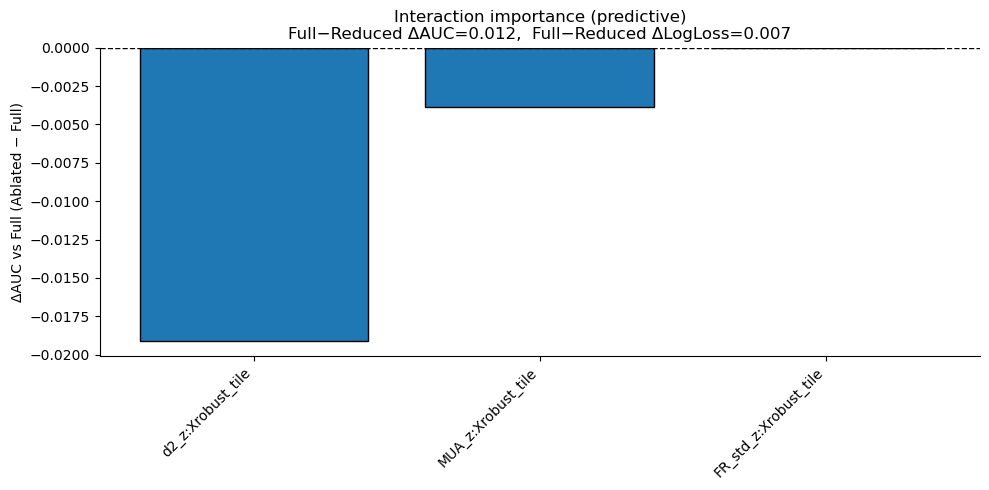

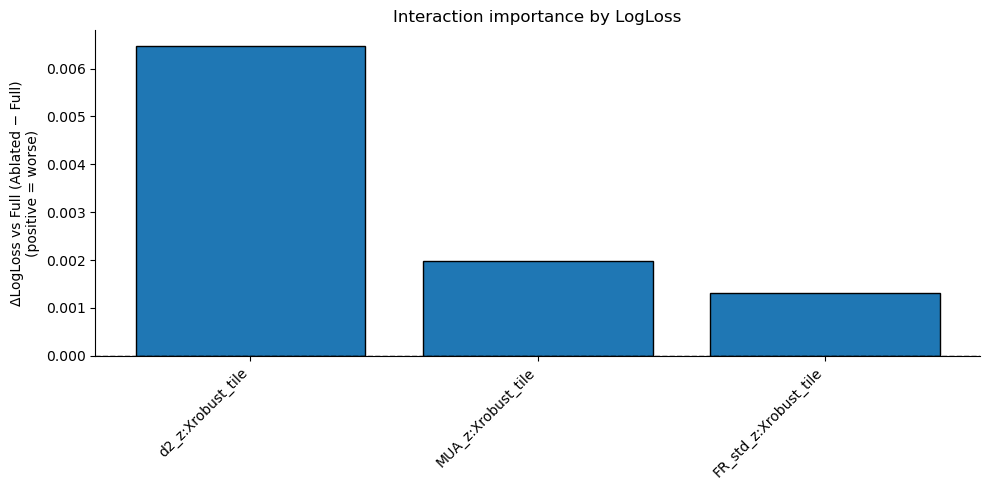

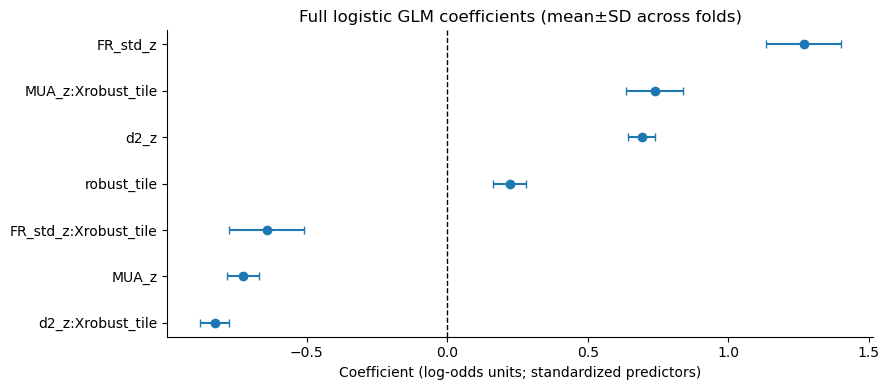

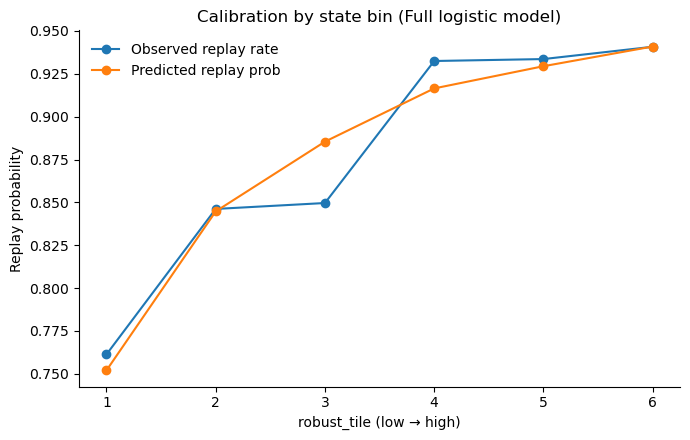

   robust_tile  obs_rate  pred_rate    n
0            1  0.761281   0.751956  687
1            2  0.846154   0.844720  702
2            3  0.849609   0.885412  512
3            4  0.932471   0.916480  696
4            5  0.933602   0.929431  497
5            6  0.940778   0.940917  591


In [435]:
import numpy as np
import pandas as pd
from scipy import stats

from sklearn.model_selection import GroupKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss


# ============================================================
# 1) Nonparametric "slope divergence"
# ============================================================
def slope_divergence_bootstrap(
    d: pd.DataFrame,
    features=("d2", "MUA", "FR_std"),
    tile_col="tile",
    replay_col="replay_present",
    n_bins=6,
    n_boot=1000,
    random_state=0,
    strict_require_both=True,   # require both replay & non-replay per bin
):
    """
    Computes slope of Δ(b) across bins where Δ(b) = mean(feature|replay=1,bin) - mean(feature|replay=0,bin),
    with bootstrap over rows. Returns:
      summ_df: per-feature mean slope + bootstrap SE
      raw_df:  per-bootstrap slopes
      df_work: processed dataframe with robust_tile + z-scored features
    """
    rng = np.random.default_rng(random_state)

    features = [f for f in features if f in d.columns]
    if len(features) == 0:
        raise ValueError("No requested features found in dataframe.")

    df = d.dropna(subset=[tile_col, replay_col] + features).copy()

    # robust bins
    if df[tile_col].nunique() > n_bins or df[tile_col].max() > n_bins:
        df["robust_tile"] = pd.qcut(df[tile_col], q=n_bins, labels=False, duplicates="drop")
    else:
        df["robust_tile"] = df[tile_col].astype(int)

    # z-score features (global; for within-session, z-score before calling)
    for f in features:
        mu = df[f].mean()
        sd = df[f].std(ddof=1)
        df[f"{f}_z"] = (df[f] - mu) / (sd if sd > 0 else 1.0)

    bins = np.sort(df["robust_tile"].unique())
    boot_slopes = {f: [] for f in features}

    for bi in range(n_boot):
        sample = df.sample(frac=1.0, replace=True, random_state=int(rng.integers(0, 1e9)))
        grouped = sample.groupby(["robust_tile", replay_col])[[f"{f}_z" for f in features]].mean()

        for f in features:
            deltas, x = [], []
            for b in bins:
                # require replay=1
                if (b, 1) not in grouped.index:
                    continue
                # require replay=0 if strict
                if strict_require_both and (b, 0) not in grouped.index:
                    continue

                val_in = grouped.loc[(b, 1), f"{f}_z"]
                if (b, 0) in grouped.index:
                    val_out = grouped.loc[(b, 0), f"{f}_z"]
                else:
                    # fallback anchor
                    val_out = 0.0

                deltas.append(val_in - val_out)
                x.append(b)

            if len(deltas) >= 2:
                slope, *_ = stats.linregress(x, deltas)
                boot_slopes[f].append(slope)
            else:
                boot_slopes[f].append(np.nan)

    raw_rows = []
    summ_rows = []
    for f in features:
        slopes = np.asarray(boot_slopes[f], float)
        slopes = slopes[np.isfinite(slopes)]
        raw_rows.extend([{"Feature": f, "Slope": s} for s in slopes])

        if len(slopes) == 0:
            mean_slope, se = np.nan, np.nan
            n_ok = 0
        else:
            mean_slope = slopes.mean()
            se = slopes.std(ddof=1)  # bootstrap SE
            n_ok = len(slopes)

        summ_rows.append({"Feature": f, "Mean_Slope": mean_slope, "Boot_SE": se, "N_Valid_Boot": n_ok})

    summ_df = pd.DataFrame(summ_rows).sort_values("Feature")
    raw_df = pd.DataFrame(raw_rows)

    return summ_df, raw_df, df


# ============================================================
# 2) Predictive GLM (logistic regression) + ablation gain
#    Predict replay_present from features + (feature × state-bin) interactions
# ============================================================
def _build_design(df, features, state_col="robust_tile", add_interactions=True):
    """
    Returns X matrix and column names.
    Interactions are feature_z * state (state treated numeric).
    """
    cols = []
    X_list = []

    # state
    s = df[state_col].astype(float).to_numpy().reshape(-1, 1)
    X_list.append(s)
    cols.append(state_col)

    # main effects
    for f in features:
        z = df[f"{f}_z"].to_numpy().reshape(-1, 1)
        X_list.append(z)
        cols.append(f"{f}_z")

    # interactions
    if add_interactions:
        for f in features:
            z = df[f"{f}_z"].to_numpy().reshape(-1, 1)
            X_list.append(z * s)
            cols.append(f"{f}_z:X{state_col}")

    X = np.hstack(X_list)
    return X, cols


def cv_predictive_gain_logistic(
    d: pd.DataFrame,
    features=("d2", "MUA", "FR_std"),
    tile_col="tile",
    replay_col="replay_present",
    n_bins=6,
    group_col=None,       # e.g. "session" or "file"
    n_splits=5,
    C=1.0,                # inverse regularization strength (bigger = less reg)
    random_state=0,
):
    """
    Cross-validated predictive performance for:
      - reduced model: main effects only (state + features)
      - full model:    main + interactions (feature × state)
    Plus ablation: drop each interaction term one-at-a-time from the full model.

    Returns:
      results_df (summary), details (dict with fold-wise metrics)
    """
    # ---------- preprocess (same robust tiles + zscores) ----------
    summ_df, raw_df, df = slope_divergence_bootstrap(
        d, features=features, tile_col=tile_col, replay_col=replay_col, n_bins=n_bins,
        n_boot=50,  # not used for prediction
        random_state=random_state,
        strict_require_both=False
    )
    # keep only usable rows
    features = [f for f in features if f in df.columns]
    df = df.dropna(subset=[replay_col, "robust_tile"] + [f"{f}_z" for f in features]).copy()

    y = df[replay_col].astype(int).to_numpy()

    # grouping / splits
    if group_col is not None and group_col in df.columns:
        groups = df[group_col].to_numpy()
        splitter = GroupKFold(n_splits=n_splits)
        splits = list(splitter.split(df, y, groups=groups))
    else:
        splitter = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
        splits = list(splitter.split(df, y))

    # models
    # Use liblinear for smaller datasets; saga works too.
    def fit_eval(X, y, splits):
        aucs, lls = [], []
        for tr, te in splits:
            Xtr, Xte = X[tr], X[te]
            ytr, yte = y[tr], y[te]

            # standardize predictors *within fold* for clean CV
            sc = StandardScaler(with_mean=True, with_std=True)
            Xtr_s = sc.fit_transform(Xtr)
            Xte_s = sc.transform(Xte)

            clf = LogisticRegression(
                penalty="l2",
                C=C,
                solver="liblinear",
                max_iter=2000,
                random_state=random_state
            )
            clf.fit(Xtr_s, ytr)
            p = clf.predict_proba(Xte_s)[:, 1]

            aucs.append(roc_auc_score(yte, p))
            lls.append(log_loss(yte, p, labels=[0, 1]))

        return np.array(aucs), np.array(lls)

    # ---------- Reduced model (no interactions) ----------
    X_red, red_cols = _build_design(df, features, state_col="robust_tile", add_interactions=False)
    auc_red, ll_red = fit_eval(X_red, y, splits)

    # ---------- Full model (with interactions) ----------
    X_full, full_cols = _build_design(df, features, state_col="robust_tile", add_interactions=True)
    auc_full, ll_full = fit_eval(X_full, y, splits)

    # predictive gain (higher AUC better; lower logloss better)
    gain_auc = auc_full.mean() - auc_red.mean()
    gain_ll  = ll_red.mean() - ll_full.mean()

    rows = [{
        "Model": "Reduced (main effects)",
        "AUC_mean": auc_red.mean(), "AUC_sd": auc_red.std(ddof=1),
        "LogLoss_mean": ll_red.mean(), "LogLoss_sd": ll_red.std(ddof=1),
        "n": len(df)
    },{
        "Model": "Full (main + interactions)",
        "AUC_mean": auc_full.mean(), "AUC_sd": auc_full.std(ddof=1),
        "LogLoss_mean": ll_full.mean(), "LogLoss_sd": ll_full.std(ddof=1),
        "n": len(df)
    },{
        "Model": "Gain (Full - Reduced)",
        "AUC_mean": gain_auc, "AUC_sd": np.nan,
        "LogLoss_mean": gain_ll, "LogLoss_sd": np.nan,
        "n": len(df)
    }]

    # ---------- Ablate each interaction one-at-a-time ----------
    # Identify interaction columns in full design
    inter_idx = [i for i, c in enumerate(full_cols) if ":Xrobust_tile" in c]
    base_auc, base_ll = auc_full.mean(), ll_full.mean()

    for idx in inter_idx:
        keep = [i for i in range(X_full.shape[1]) if i != idx]
        X_ab = X_full[:, keep]
        auc_ab, ll_ab = fit_eval(X_ab, y, splits)

        rows.append({
            "Model": f"Ablate {full_cols[idx]}",
            "AUC_mean": auc_ab.mean(), "AUC_sd": auc_ab.std(ddof=1),
            "LogLoss_mean": ll_ab.mean(), "LogLoss_sd": ll_ab.std(ddof=1),
            "ΔAUC_vs_Full": auc_ab.mean() - base_auc,
            "ΔLogLoss_vs_Full": ll_ab.mean() - base_ll,
            "n": len(df)
        })

    results_df = pd.DataFrame(rows)

    details = {
        "slope_divergence_summary_quick": summ_df,   # quick check only
        "reduced": {"cols": red_cols, "auc": auc_red, "logloss": ll_red},
        "full":    {"cols": full_cols, "auc": auc_full, "logloss": ll_full},
        "splits": splits,
        "df_used": df
    }
    return results_df, details


# ============================================================
# 3) Example usage
# ============================================================
# Pass the session/file ID as group_col to avoid leakage.
# e.g., group_col="file" or group_col="session"

# ---- A) Your mechanistic summary (slope divergence) ----
# summ_df, raw_df, df_work = slope_divergence_bootstrap(d, tile_col="tile", replay_col="replay_present", n_bins=6, n_boot=1000)

# ---- B) Predictive strength + ablation (GLM-ish) ----
results_df, details = cv_predictive_gain_logistic(
    d,
    features=("d2", "MUA", "FR_std"),
    tile_col="tile",
    replay_col="replay_present",
    n_bins=6,
    group_col="session",   # None if not available
    n_splits=5,
    C=1.0,
    random_state=0
)
# print(results_df.sort_values("Model").to_string(index=False))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss


def _despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)


def plot_glm_gain_from_results(results_df, title="Predictive gain from interactions"):
    """
    Plots Full-vs-Reduced gain and each interaction ablation's ΔAUC / ΔLogLoss vs Full.
    Expects results_df returned by cv_predictive_gain_logistic.
    """
    df = results_df.copy()

    # ---- Gain summary (Full - Reduced) ----
    gain_row = df[df["Model"] == "Gain (Full - Reduced)"]
    if len(gain_row) != 1:
        print("Could not find Gain (Full - Reduced) row. Plotting ablations only.")
        gain_auc = np.nan
        gain_ll = np.nan
    else:
        gain_auc = float(gain_row["AUC_mean"].iloc[0])
        gain_ll  = float(gain_row["LogLoss_mean"].iloc[0])

    # ---- Ablations ----
    ab = df[df["Model"].str.startswith("Ablate")].copy()
    if len(ab) == 0:
        print("No ablation rows found. Nothing to plot.")
        return

    # Sort by ΔAUC (most harmful drop first = most negative)
    if "ΔAUC_vs_Full" in ab.columns:
        ab = ab.sort_values("ΔAUC_vs_Full")

    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(ab))
    y = ab["ΔAUC_vs_Full"].to_numpy()

    ax.bar(x, y, edgecolor="k")
    ax.axhline(0, linestyle="--", linewidth=1, color="k")
    ax.set_xticks(x)
    ax.set_xticklabels(ab["Model"].str.replace("Ablate ", "", regex=False), rotation=45, ha="right")
    ax.set_ylabel("ΔAUC vs Full (Ablated − Full)")
    ax.set_title(f"{title}\nFull−Reduced ΔAUC={gain_auc:.3f},  Full−Reduced ΔLogLoss={gain_ll:.3f}")
    _despine(ax)
    plt.tight_layout()
    plt.show()

    # Optional LogLoss ablation plot
    if "ΔLogLoss_vs_Full" in ab.columns:
        fig, ax = plt.subplots(figsize=(10, 5))
        y2 = ab["ΔLogLoss_vs_Full"].to_numpy()
        ax.bar(x, y2, edgecolor="k")
        ax.axhline(0, linestyle="--", linewidth=1, color="k")
        ax.set_xticks(x)
        ax.set_xticklabels(ab["Model"].str.replace("Ablate ", "", regex=False), rotation=45, ha="right")
        ax.set_ylabel("ΔLogLoss vs Full (Ablated − Full)\n(positive = worse)")
        ax.set_title("Interaction importance by LogLoss")
        _despine(ax)
        plt.tight_layout()
        plt.show()


def fit_full_logistic_per_fold(details, C=1.0, random_state=0):
    """
    Refit FULL model on each CV fold to extract coefficients (standardized within fold).
    Returns coef_df with columns: term, fold, coef.
    """
    df = details["df_used"].copy()
    splits = details["splits"]
    full_cols = details["full"]["cols"]

    # Rebuild X_full via _build_design(df, features, add_interactions=True)
    # Reconstruct the features list from column names ending in _z, excluding interaction terms
    features = [c.replace("_z", "") for c in full_cols if c.endswith("_z") and ":X" not in c]

    from sklearn.model_selection import GroupKFold, KFold  # just for namespace safety

    # Same builder as above
    X_full, full_cols = _build_design(df, features, state_col="robust_tile", add_interactions=True)
    y = df["replay_present"].astype(int).to_numpy()

    coef_rows = []

    for k, (tr, te) in enumerate(splits):
        Xtr = X_full[tr]
        ytr = y[tr]

        sc = StandardScaler(with_mean=True, with_std=True)
        Xtr_s = sc.fit_transform(Xtr)

        clf = LogisticRegression(
            penalty="l2",
            C=C,
            solver="liblinear",
            max_iter=2000,
            random_state=random_state
        )
        clf.fit(Xtr_s, ytr)

        coefs = clf.coef_.ravel()
        for term, cval in zip(full_cols, coefs):
            coef_rows.append({"term": term, "fold": k, "coef": cval})

    return pd.DataFrame(coef_rows)


def plot_glm_coefficients(coef_df, title="Full model coefficients (per-fold)"):
    """
    Coefficient plot: mean ± SD across folds.
    Positive coef => increases log-odds of replay (holding others fixed).
    """
    summ = (coef_df
            .groupby("term")["coef"]
            .agg(["mean", "std"])
            .reset_index()
            .sort_values("mean"))

    fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(summ))))
    y = np.arange(len(summ))
    ax.errorbar(summ["mean"].to_numpy(), y, xerr=summ["std"].to_numpy(), fmt="o", capsize=3)
    ax.axvline(0, linestyle="--", linewidth=1, color="k")
    ax.set_yticks(y)
    ax.set_yticklabels(summ["term"])
    ax.set_xlabel("Coefficient (log-odds units; standardized predictors)")
    ax.set_title(title)
    _despine(ax)
    plt.tight_layout()
    plt.show()


def plot_predicted_replay_by_tile(details, C=1.0, random_state=0, n_bins_show=None):
    """
    Fit FULL model on all data, then plot:
      - observed replay rate per tile
      - predicted replay probability per tile (mean)
    This is a very interpretable "GLM plot" for gating.
    """
    df = details["df_used"].copy()
    full_cols = details["full"]["cols"]

    features = [c.replace("_z", "") for c in full_cols if c.endswith("_z") and ":X" not in c]
    X_full, full_cols = _build_design(df, features, state_col="robust_tile", add_interactions=True)
    y = df["replay_present"].astype(int).to_numpy()

    sc = StandardScaler(with_mean=True, with_std=True)
    Xs = sc.fit_transform(X_full)

    clf = LogisticRegression(
        penalty="l2",
        C=C,
        solver="liblinear",
        max_iter=2000,
        random_state=random_state
    )
    clf.fit(Xs, y)
    p = clf.predict_proba(Xs)[:, 1]
    df = df.copy()
    df["p_hat"] = p

    g = df.groupby("robust_tile").agg(
        obs_rate=( "replay_present", "mean"),
        pred_rate=("p_hat", "mean"),
        n=("p_hat", "size")
    ).reset_index().sort_values("robust_tile")

    if n_bins_show is not None:
        g = g.tail(n_bins_show)

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(g["robust_tile"], g["obs_rate"], marker="o", label="Observed replay rate")
    ax.plot(g["robust_tile"], g["pred_rate"], marker="o", label="Predicted replay prob")
    ax.set_xlabel("robust_tile (low → high)")
    ax.set_ylabel("Replay probability")
    ax.set_title("Calibration by state bin (Full logistic model)")
    ax.legend(frameon=False)
    _despine(ax)
    plt.tight_layout()
    plt.show()

    return g

# Plot (A) interaction importance via ablation
plot_glm_gain_from_results(results_df, title="Interaction importance (predictive)")

# Plot (B) coefficients across folds (Full model)
coef_df = fit_full_logistic_per_fold(details, C=1.0, random_state=0)
plot_glm_coefficients(coef_df, title="Full logistic GLM coefficients (mean±SD across folds)")

# Plot (C) predicted vs observed replay rate across tiles (gating visualization)
tile_calib = plot_predicted_replay_by_tile(details, C=1.0, random_state=0)
print(tile_calib)

In [ ]:

outdir = r'D:\Documents\GitHub\Sleep_criticaltiy\data\GLM_mice\explore'
os.makedirs(outdir, exist_ok=True)

# Animal and day, if not already set
# animal_name = "SuperRat"
# day = "Day1"

# Construct the filename
filename = f"{animal_name}_{day}_ablation_results_GLM.pkl"
save_path = os.path.join(outdir, filename)
# Construct a consolidated save object
save_data = {
    "summary": results_df,
    "slopes": details["slope_divergence_summary_quick"], # The "Divergence Slopes"
    "auc_folds": {
        "full": details["full"]["auc"],
        "reduced": details["reduced"]["auc"]
    },
    "n_samples": len(details["df_used"]),
    "animal": animal_name,
    "day": day
}

# Save it
save_path = os.path.join(outdir, f"{animal_name}_{day}_ablation_results_GLM.pkl")
# # Save the DataFrame
pd.to_pickle(save_data, save_path)


Saved ablation results to: D:\Documents\GitHub\Sleep_criticaltiy\data\GLM_mice\explore\PPP23_day8_ablation_results_slope.pkl
